In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df=pd.read_csv('kc_house_data_preprocessed.csv')

sns.set_theme(style="whitegrid")

print(df.head())
print(df.shape)
print(df.columns)

           id             date     price  bedrooms  bathrooms  sqft_living  \
0  7129300520  20141013T000000  221900.0         3       1.00         1180   
1  6414100192  20141209T000000  538000.0         3       2.25         2570   
2  5631500400  20150225T000000  180000.0         2       1.00          770   
3  2487200875  20141209T000000  604000.0         4       3.00         1960   
4  1954400510  20150218T000000  510000.0         3       2.00         1680   

   sqft_lot  floors  waterfront  view  ...  grade  sqft_above  sqft_basement  \
0      5650     1.0           0     0  ...      7        1180              0   
1      7242     2.0           0     0  ...      7        2170            400   
2     10000     1.0           0     0  ...      6         770              0   
3      5000     1.0           0     0  ...      7        1050            910   
4      8080     1.0           0     0  ...      8        1680              0   

   yr_built  yr_renovated  zipcode      lat     lo

In [ ]:
df.head()

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3.0,1.00,1180.0,5650.0,1.0,0.0,0.0,...,7.0,1180.0,0.0,1955.0,0.0,98178.0,47.5112,-122.257,1340.0,5650.0
1,6414100192,20141209T000000,538000.0,3.0,2.25,2570.0,7242.0,2.0,0.0,0.0,...,7.0,2170.0,400.0,1951.0,1991.0,98125.0,47.7210,-122.319,1690.0,7639.0
2,5631500400,20150225T000000,180000.0,2.0,1.00,770.0,10000.0,1.0,0.0,0.0,...,6.0,770.0,0.0,1933.0,0.0,98028.0,47.7379,-122.233,2720.0,8062.0
3,2487200875,20141209T000000,604000.0,4.0,3.00,1960.0,5000.0,1.0,0.0,0.0,...,7.0,1050.0,910.0,1965.0,0.0,98136.0,47.5208,-122.393,1360.0,5000.0
4,1954400510,20150218T000000,510000.0,3.0,2.00,1680.0,8080.0,1.0,0.0,0.0,...,8.0,1680.0,0.0,1987.0,0.0,98074.0,47.6168,-122.045,1800.0,7503.0


In [ ]:
df.columns

Index(['id', 'date', 'price', 'bedrooms', 'bathrooms', 'sqft_living',
       'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade',
       'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'zipcode',
       'lat', 'long', 'sqft_living15', 'sqft_lot15'],
      dtype='object')

In [ ]:
df['date']=pd.to_datetime(df['date'],errors='coerce')

df['sale_year']=df['date'].dt.year

df['property_age']=df['sale_year']-df['yr_built']

df['is_renovated']=np.where(df['yr_renovated']>0,'Renovated','Not Renovated')

df['price_per_sqft_living']=df['price']/df['sqft_living'].replace(0,np.nan)

df['price_per_sqft_lot']=df['price']/df['sqft_lot'].replace(0,np.nan)

df=df.dropna(subset=['price','sqft_living','lat','long'])

print(df[['price','sqft_living','sale_year','property_age','is_renovated','price_per_sqft_living']].head())

      price  sqft_living  sale_year  property_age   is_renovated  \
0  221900.0         1180       2014            59  Not Renovated   
1  538000.0         2570       2014            63      Renovated   
2  180000.0          770       2015            82  Not Renovated   
3  604000.0         1960       2014            49  Not Renovated   
4  510000.0         1680       2015            28  Not Renovated   

   price_per_sqft_living  
0             188.050847  
1             209.338521  
2             233.766234  
3             308.163265  
4             303.571429  


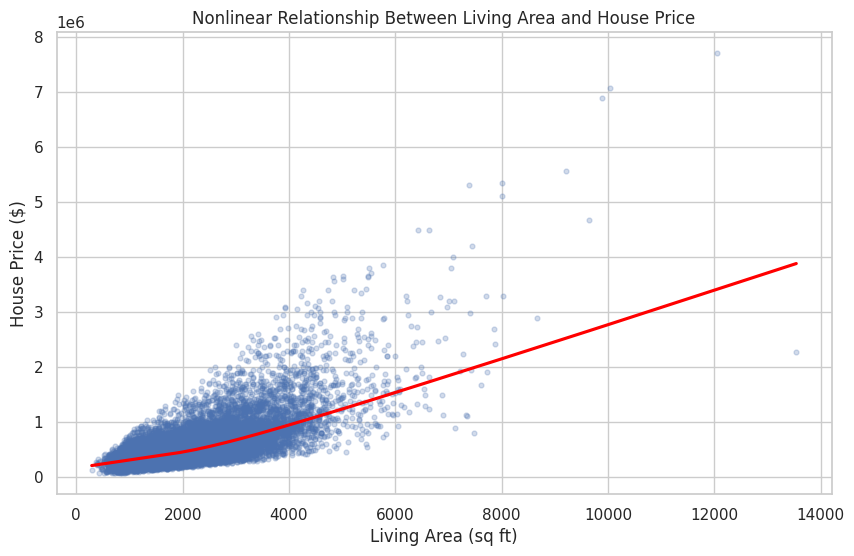

In [ ]:
plt.figure(figsize=(10,6))

sns.regplot(data=df,x='sqft_living',y='price',
            lowess=True,
            scatter_kws={'alpha':0.25,'s':12},
            line_kws={'color':'red'})

plt.title('Nonlinear Relationship Between Living Area and House Price')
plt.xlabel('Living Area (sq ft)')
plt.ylabel('House Price ($)')
plt.show()

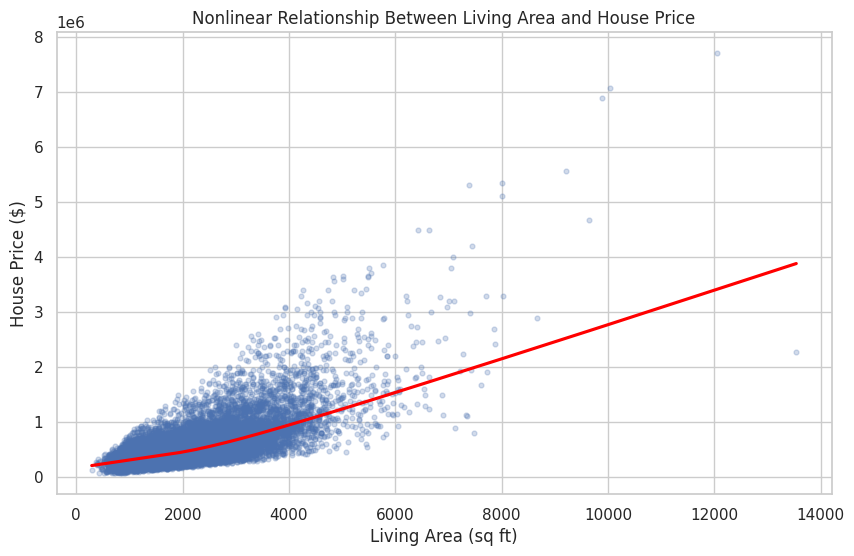

In [ ]:
plt.figure(figsize=(10,6))

sns.regplot(data=df,x='sqft_living',y='price',
            lowess=True,
            scatter_kws={'alpha':0.25,'s':12},
            line_kws={'color':'red'})

plt.title('Nonlinear Relationship Between Living Area and House Price')
plt.xlabel('Living Area (sq ft)')
plt.ylabel('House Price ($)')
plt.show()

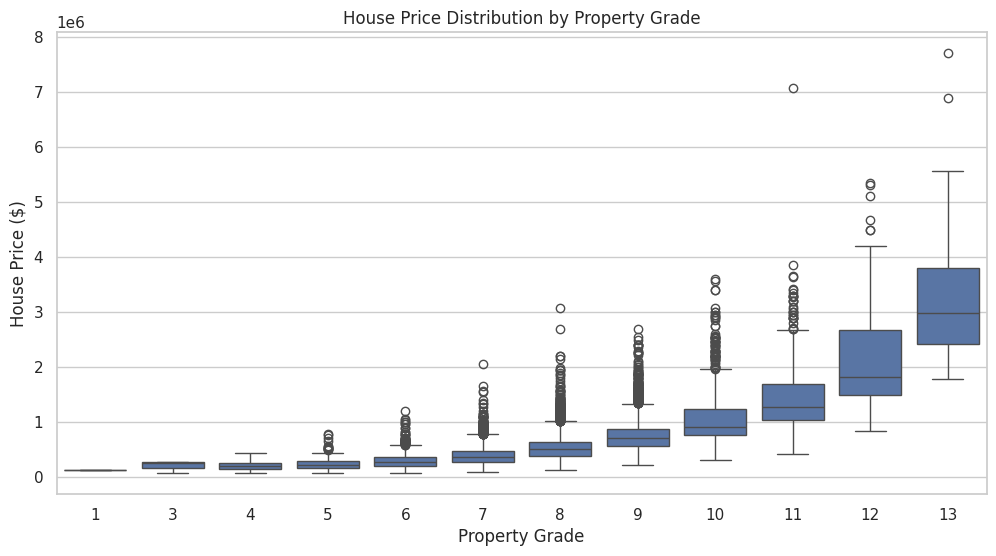

In [ ]:
plt.figure(figsize=(12,6))

sns.boxplot(data=df,x='grade',y='price')

plt.title('House Price Distribution by Property Grade')
plt.xlabel('Property Grade')
plt.ylabel('House Price ($)')
plt.show()

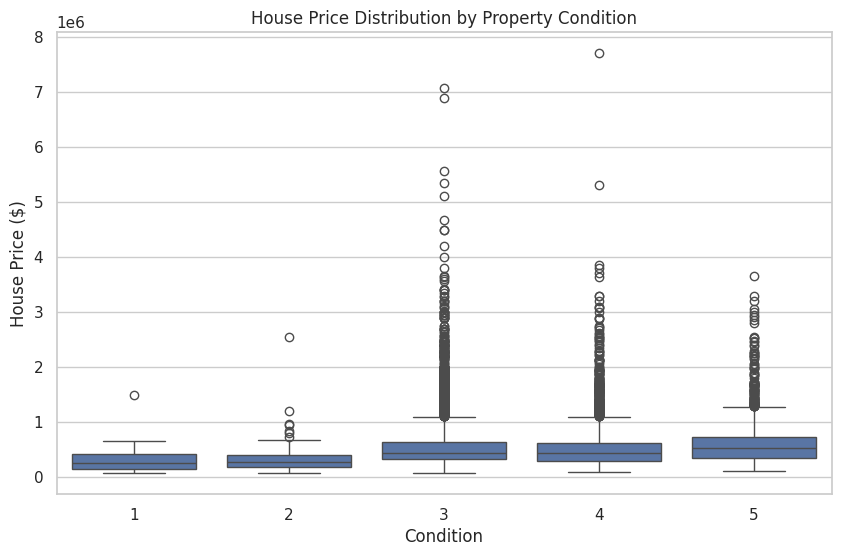

In [ ]:
plt.figure(figsize=(10,6))

sns.boxplot(data=df,x='condition',y='price')

plt.title('House Price Distribution by Property Condition')
plt.xlabel('Condition')
plt.ylabel('House Price ($)')
plt.show()

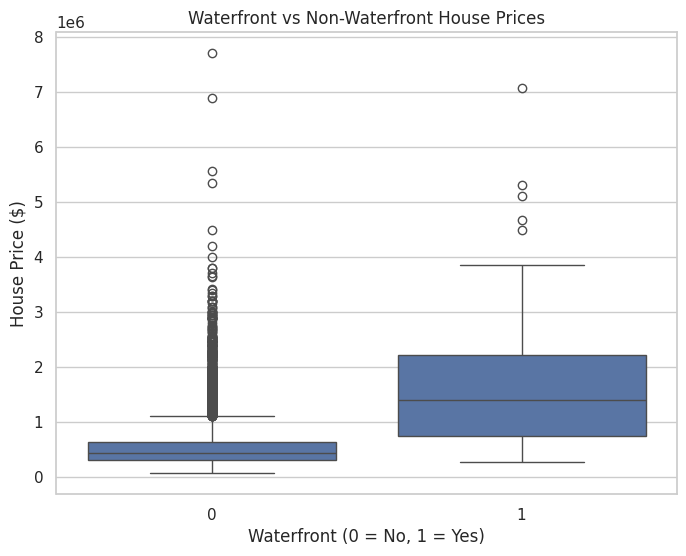

In [ ]:
plt.figure(figsize=(8,6))

sns.boxplot(data=df,x='waterfront',y='price')

plt.title('Waterfront vs Non-Waterfront House Prices')
plt.xlabel('Waterfront (0 = No, 1 = Yes)')
plt.ylabel('House Price ($)')
plt.show()

In [ ]:
waterfront_prices=df.groupby('waterfront')['price'].agg(['mean','median','count'])

print(waterfront_prices)

if 0 in waterfront_prices.index and 1 in waterfront_prices.index:
    no_waterfront=waterfront_prices.loc[0,'mean']
    with_waterfront=waterfront_prices.loc[1,'mean']

    premium=((with_waterfront-no_waterfront)/no_waterfront)*100

    print("Observed Average Price Difference: $",round(with_waterfront-no_waterfront,2))
    print("Observed Waterfront Price Premium:",round(premium,2),"%")

                    mean     median  count
waterfront                                
0           5.315636e+05   450000.0  21450
1           1.661876e+06  1400000.0    163
Observed Average Price Difference: $ 1130312.42
Observed Waterfront Price Premium: 212.64 %


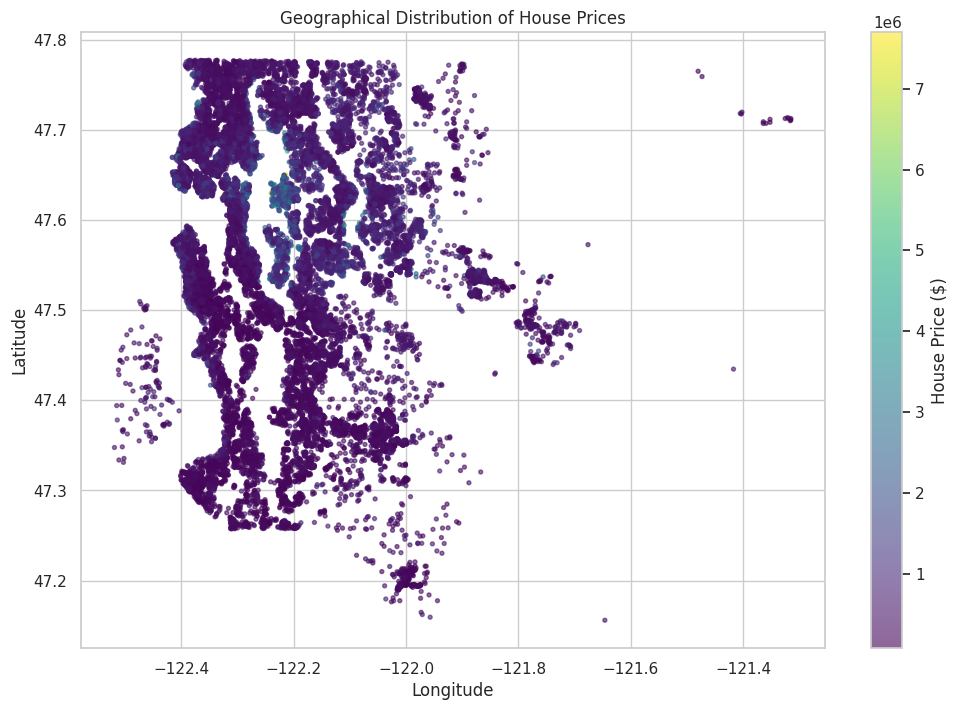

In [ ]:
plt.figure(figsize=(12,8))

scatter=plt.scatter(df['long'],df['lat'],
                    c=df['price'],
                    cmap='viridis',
                    s=8,
                    alpha=0.6)

plt.colorbar(scatter,label='House Price ($)')
plt.title('Geographical Distribution of House Prices')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()

Top 10 ZIP Codes by Median House Price
         median_price  average_price  number_of_houses  average_grade  \
zipcode                                                                 
98039       1892500.0   2.160607e+06                50       9.560000   
98004       1150000.0   1.355927e+06               317       8.687697   
98040        993750.0   1.194230e+06               282       8.960993   
98112        915000.0   1.095499e+06               269       8.442379   
98005        765475.0   8.101649e+05               168       8.488095   
98006        760184.5   8.596848e+05               498       8.795181   
98119        744975.0   8.494480e+05               184       8.021739   
98075        739999.0   7.905767e+05               359       9.008357   
98109        736000.0   8.796236e+05               109       8.018349   
98102        720000.0   9.012583e+05               105       8.285714   

         average_living_area  
zipcode                       
98039            3800.

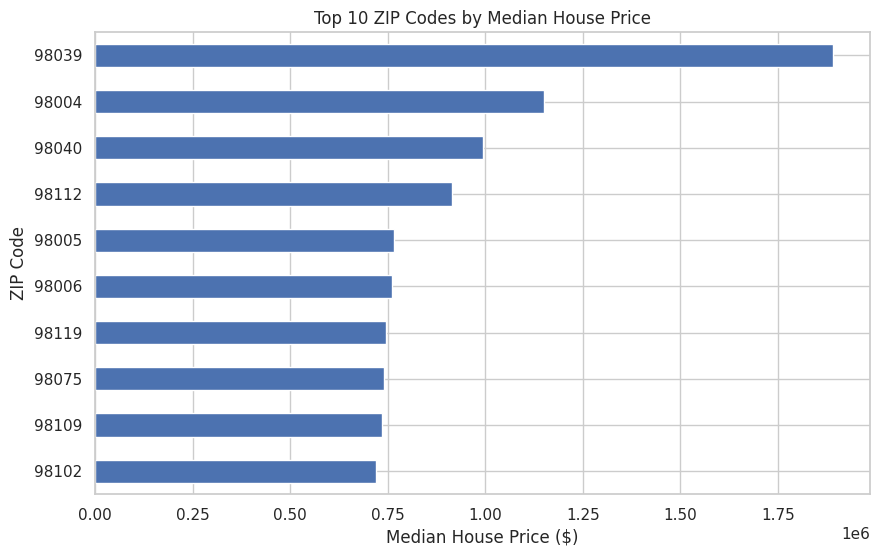

In [ ]:
zipcode_prices=df.groupby('zipcode').agg(
    median_price=('price','median'),
    average_price=('price','mean'),
    number_of_houses=('price','count'),
    average_grade=('grade','mean'),
    average_living_area=('sqft_living','mean')
).sort_values('median_price',ascending=False)

print("Top 10 ZIP Codes by Median House Price")
print(zipcode_prices.head(10))

top_zips=zipcode_prices.head(10).sort_values('median_price')

plt.figure(figsize=(10,6))

top_zips['median_price'].plot(kind='barh')

plt.title('Top 10 ZIP Codes by Median House Price')
plt.xlabel('Median House Price ($)')
plt.ylabel('ZIP Code')
plt.show()

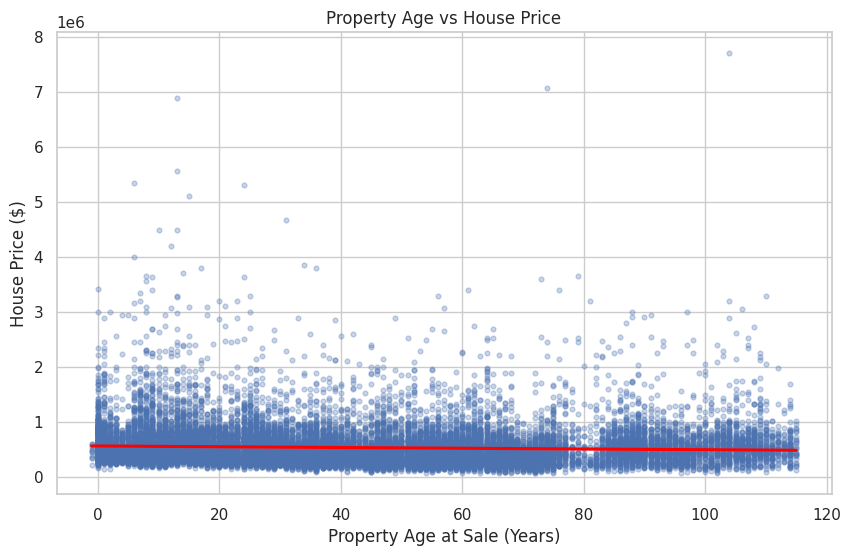

In [ ]:
plt.figure(figsize=(10,6))

sns.regplot(data=df,x='property_age',y='price',
            scatter_kws={'alpha':0.3,'s':12},
            line_kws={'color':'red'})

plt.title('Property Age vs House Price')
plt.xlabel('Property Age at Sale (Years)')
plt.ylabel('House Price ($)')
plt.show()

is_renovated
Not Renovated    530360.818155
Renovated        760379.029540
Name: price, dtype: float64


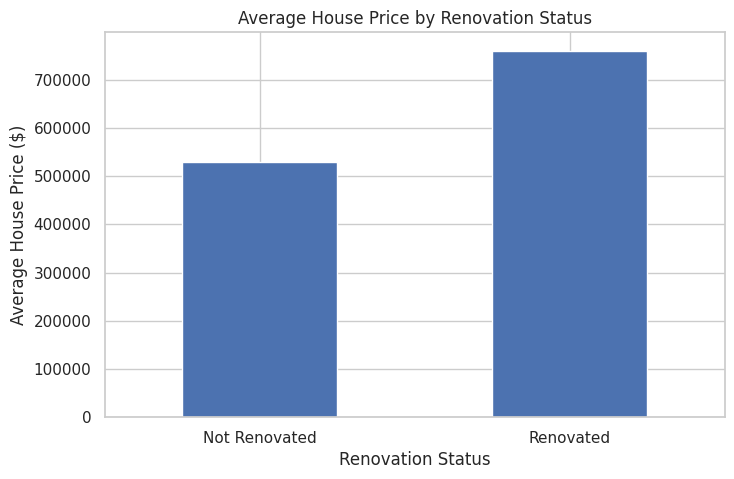

In [ ]:
renovation_prices=df.groupby('is_renovated')['price'].mean()

print(renovation_prices)

renovation_prices.plot(kind='bar',figsize=(8,5))

plt.title('Average House Price by Renovation Status')
plt.xlabel('Renovation Status')
plt.ylabel('Average House Price ($)')
plt.xticks(rotation=0)
plt.show()

grade
1     489.655172
3     360.817706
4     362.381152
5     278.933609
6     270.991691
7     251.902028
8     258.086806
9     275.767174
10    307.589375
11    342.249732
12    401.853756
13    483.650379
Name: price_per_sqft_living, dtype: float64


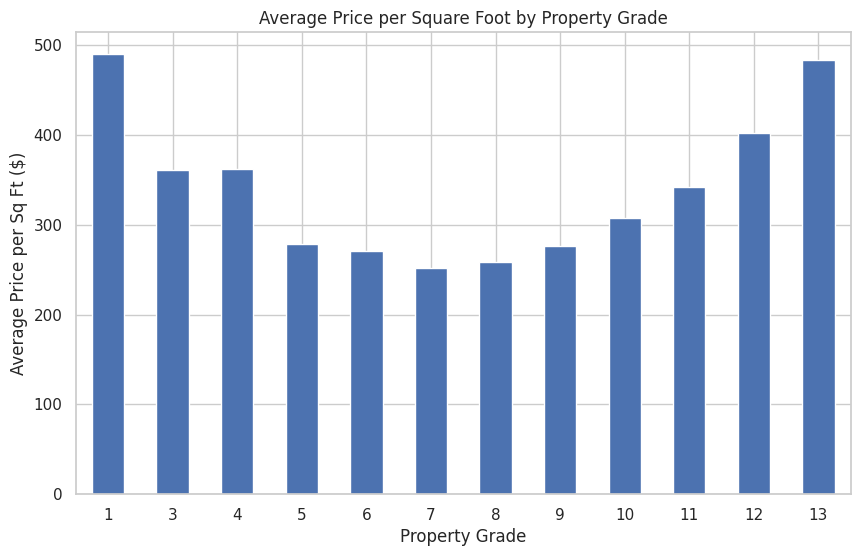

In [ ]:
grade_prices=df.groupby('grade')['price_per_sqft_living'].mean()

print(grade_prices)

grade_prices.plot(kind='bar',figsize=(10,6))

plt.title('Average Price per Square Foot by Property Grade')
plt.xlabel('Property Grade')
plt.ylabel('Average Price per Sq Ft ($)')
plt.xticks(rotation=0)
plt.show()

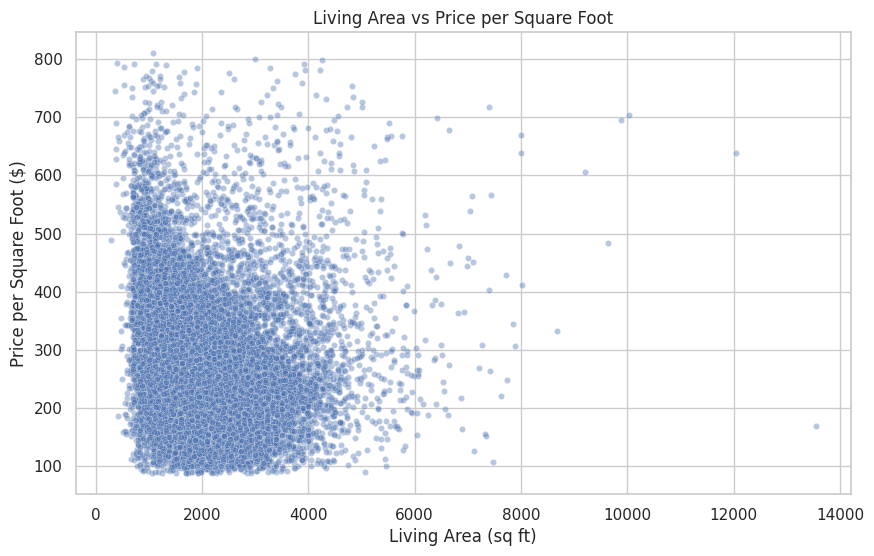

In [ ]:
plt.figure(figsize=(10,6))

sns.scatterplot(data=df,x='sqft_living',y='price_per_sqft_living',
                alpha=0.4,s=20)

plt.title('Living Area vs Price per Square Foot')
plt.xlabel('Living Area (sq ft)')
plt.ylabel('Price per Square Foot ($)')
plt.show()

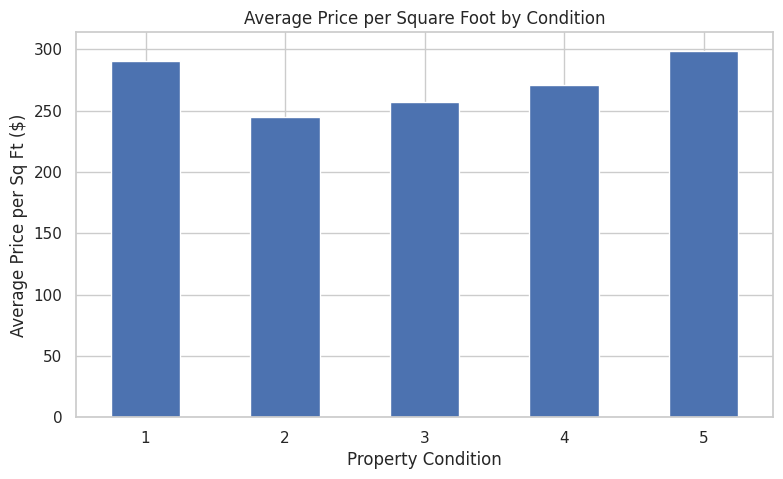

In [ ]:
condition_prices=df.groupby('condition')['price_per_sqft_living'].mean()

condition_prices.plot(kind='bar',figsize=(9,5))

plt.title('Average Price per Square Foot by Condition')
plt.xlabel('Property Condition')
plt.ylabel('Average Price per Sq Ft ($)')
plt.xticks(rotation=0)
plt.show()

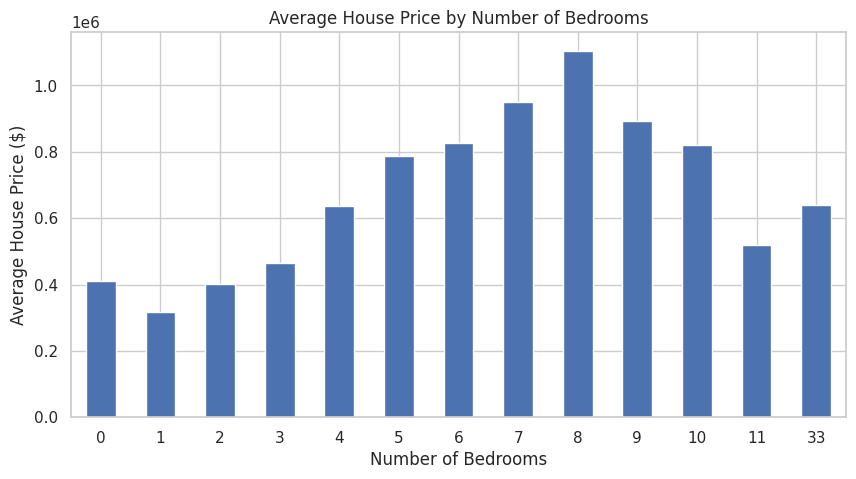

In [ ]:
bedroom_prices=df.groupby('bedrooms')['price'].mean()

bedroom_prices.plot(kind='bar',figsize=(10,5))

plt.title('Average House Price by Number of Bedrooms')
plt.xlabel('Number of Bedrooms')
plt.ylabel('Average House Price ($)')
plt.xticks(rotation=0)
plt.show()

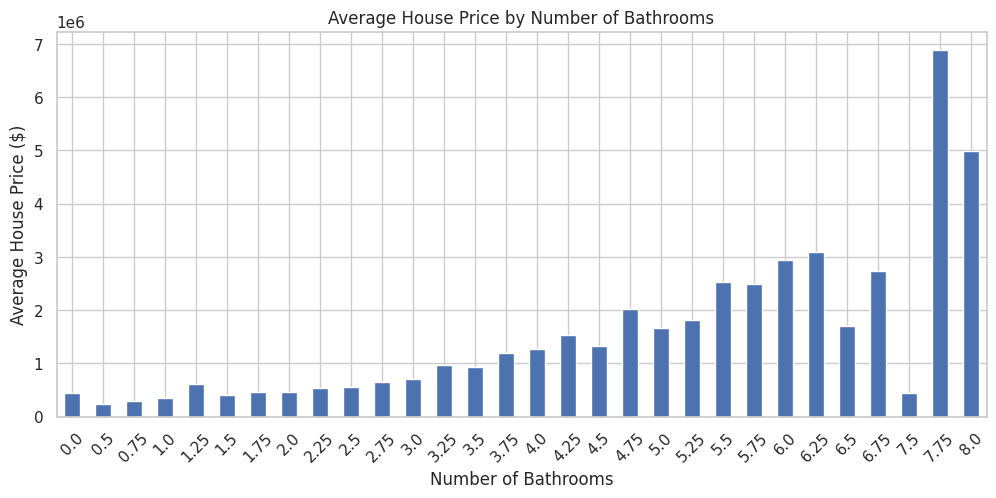

In [ ]:
bathroom_prices=df.groupby('bathrooms')['price'].mean()

bathroom_prices.plot(kind='bar',figsize=(12,5))

plt.title('Average House Price by Number of Bathrooms')
plt.xlabel('Number of Bathrooms')
plt.ylabel('Average House Price ($)')
plt.xticks(rotation=45)
plt.show()

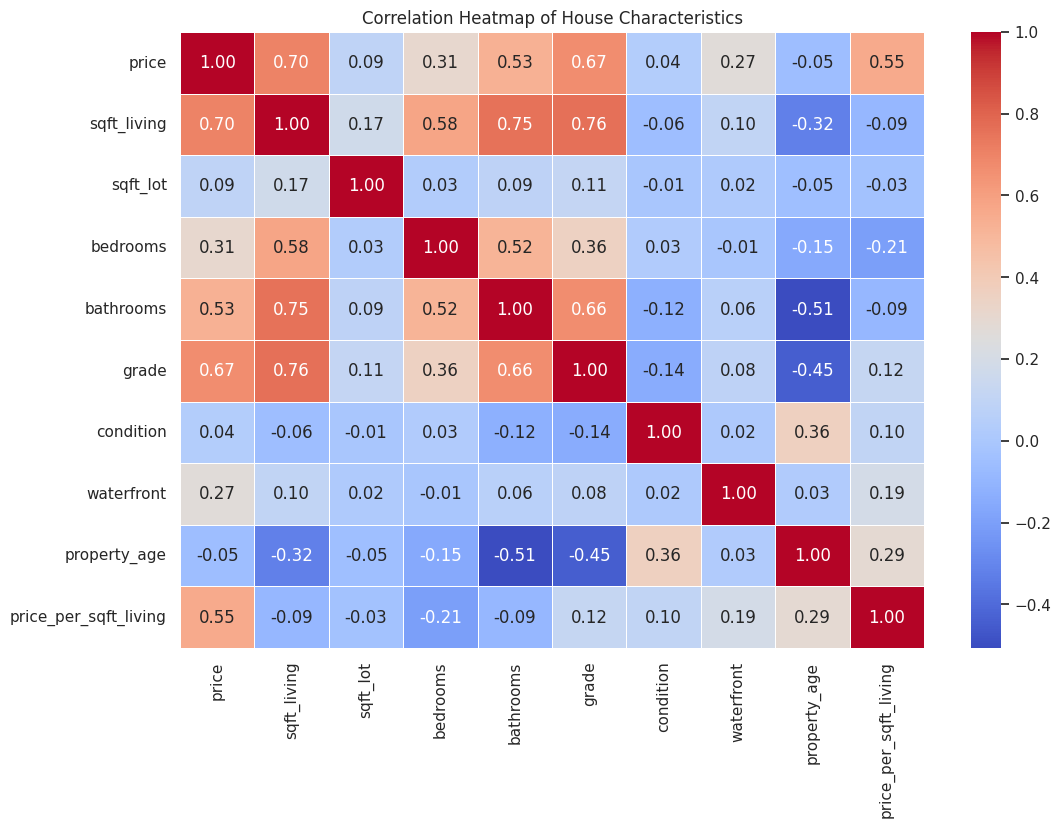

In [ ]:
columns=['price','sqft_living','sqft_lot','bedrooms',
         'bathrooms','grade','condition','waterfront',
         'property_age','price_per_sqft_living']

correlation=df[columns].corr()

plt.figure(figsize=(12,8))

sns.heatmap(correlation,annot=True,cmap='coolwarm',
            fmt='.2f',linewidths=0.5)

plt.title('Correlation Heatmap of House Characteristics')
plt.show()

In [ ]:
from sklearn.linear_model import LinearRegression

model=LinearRegression()

X=df[['sqft_living']]
y=df['price']

model.fit(X,y)

df['predicted_price']=model.predict(X)
df['price_difference']=df['price']-df['predicted_price']

high_value=df.sort_values('price_difference',ascending=False).head(10)
low_value=df.sort_values('price_difference').head(10)

print("10 Houses Priced Highest Above the Linear Trend")
print(high_value[['id','price','sqft_living','grade','waterfront','zipcode','price_difference']])

print("\n10 Houses Priced Lowest Below the Linear Trend")
print(low_value[['id','price','sqft_living','grade','waterfront','zipcode','price_difference']])

10 Houses Priced Highest Above the Linear Trend
               id      price  sqft_living  grade  waterfront  zipcode  \
7252   6762700020  7700000.0        12050     13           0    98102   
3914   9808700762  7062500.0        10040     11           1    98004   
9254   9208900037  6885000.0         9890     13           0    98039   
1315   7558700030  5300000.0         7390     12           1    98040   
1448   8907500070  5350000.0         8000     12           0    98004   
4411   2470100110  5570000.0         9200     13           0    98039   
1164   1247600105  5110800.0         8010     12           1    98033   
8638   3835500195  4489000.0         6430     12           0    98004   
2626   7738500731  4500000.0         6640     12           1    98155   
15255  2425049063  3640900.0         4830     11           1    98039   

       price_difference  
7252       4.362067e+06  
3914       4.288620e+06  
9254       4.153214e+06  
1315       3.269773e+06  
1448       3.14859

                     Top 10 Expensive ZIP Codes  Bottom 10 ZIP Codes
median_price                      941788.350000        260020.200000
average_living_area                 2709.710494          1754.189444
average_grade                          8.626850             7.066485


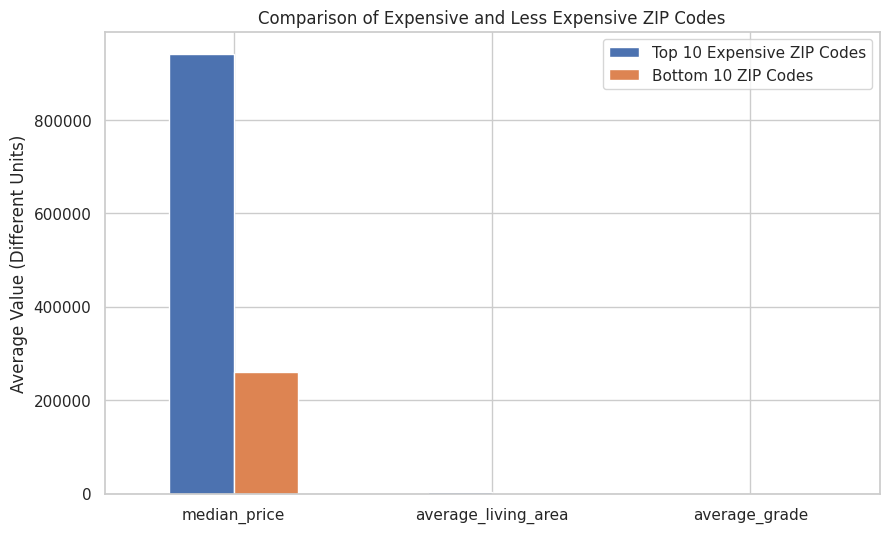

In [ ]:
top10=zipcode_prices.head(10)
bottom10=zipcode_prices.tail(10)

comparison=pd.DataFrame({
    'Top 10 Expensive ZIP Codes':top10[['median_price','average_living_area','average_grade']].mean(),
    'Bottom 10 ZIP Codes':bottom10[['median_price','average_living_area','average_grade']].mean()
})

print(comparison)

comparison.plot(kind='bar',figsize=(10,6))

plt.title('Comparison of Expensive and Less Expensive ZIP Codes')
plt.ylabel('Average Value (Different Units)')
plt.xticks(rotation=0)
plt.show()

In [ ]:
print("REAL-ESTATE ANALYSIS SUMMARY")

print("\n1. Overall House Prices")
print("Average Price: $",round(df['price'].mean(),2))
print("Median Price: $",round(df['price'].median(),2))

print("\n2. Living Area")
print("Correlation between Living Area and Price:",
      round(df['sqft_living'].corr(df['price']),3))

print("\n3. Property Grade")
print(df.groupby('grade')['price'].median().sort_values(ascending=False).head())

print("\n4. Property Condition")
print(df.groupby('condition')['price'].median().sort_values(ascending=False))

print("\n5. Waterfront")
print(df.groupby('waterfront')['price'].agg(['mean','median','count']))

print("\n6. Renovation")
print(df.groupby('is_renovated')['price'].agg(['mean','median','count']))

print("\n7. Property Age")
print("Correlation between Property Age and Price:",
      round(df['property_age'].corr(df['price']),3))

print("\n8. Most Expensive ZIP Codes by Median Price")
print(zipcode_prices[['median_price','average_living_area','average_grade']].head(10))

REAL-ESTATE ANALYSIS SUMMARY

1. Overall House Prices
Average Price: $ 540088.14
Median Price: $ 450000.0

2. Living Area
Correlation between Living Area and Price: 0.702

3. Property Grade
grade
13    2983000.0
12    1817500.0
11    1284000.0
10     914327.0
9      720000.0
Name: price, dtype: float64

4. Property Condition
condition
5    526000.0
3    450000.0
4    440000.0
2    279000.0
1    262500.0
Name: price, dtype: float64

5. Waterfront
                    mean     median  count
waterfront                                
0           5.315636e+05   450000.0  21450
1           1.661876e+06  1400000.0    163

6. Renovation
                        mean    median  count
is_renovated                                 
Not Renovated  530360.818155  448000.0  20699
Renovated      760379.029540  600000.0    914

7. Property Age
Correlation between Property Age and Price: -0.054

8. Most Expensive ZIP Codes by Median Price
         median_price  average_living_area  average_grade
zipcode 